# Scalar decays and lepton-flavour-violating Higgs rates in the 3HDM-S₃

**A research notebook, not a tutorial.** Third of the arc:
[`01_scalar_parameter_space.ipynb`](01_scalar_parameter_space.ipynb) found the viable
quartic region, [`02_s3_fermion_sector.ipynb`](02_s3_fermion_sector.ipynb) built and checked
the Yukawa sectors, and this one finally computes rates. `LFVHD_3HDMS3.tex` [LFVHD] was
written to ask what the LFV Higgs branching ratios are; notebook 02 produced the $Q_i$
matrices that carry that physics, and nothing so far turned them into a number.

`NOTES.md` recorded three blockers for this notebook. Two are gone (the fermion sector
exists; the gauge sector is three lines). The third — *"the physical basis is never
registered on the `Model`"* — is what §1 does.

## The controlling choice: general δ

The physical CP-even basis is $R_S=R_A\,R_H(\delta)$ with $\delta=\alpha-\theta_v$
([LFVHD] Eqs. RS_AH, R_H). **δ is kept symbolic throughout.** The draft's Scenario A is
$\delta\to0$ and Scenario B is $\delta\to\pi/2$; both appear here only as *limits*. And δ
is not a free dial: $\alpha$ is the residual CP-even mixing angle that
`model.cp_even_angle` computes, so at each benchmark point the λ's **predict** which
scenario the model realises (§3).

## What this notebook establishes

1. $g_{h_0VV}=0$ **exactly, for any δ** — $h_0$ is gauge-phobic while keeping its LFV
   entries. The other two share the SM coupling as $\cos\delta$/$\sin\delta$, an exact sum
   rule (§2).
2. δ is *predicted* at every viable point, giving a **coupling-based** SM-likeness cut that
   notebook 01 (mass-only) could not apply (§3).
3. The draft's Scenario-C relations, printed with "$\approx$", are **exact for all δ** (§4).
4. Two library gaps closed on the way: **VSS decays** ($A\to Zh$, $H^\pm\to W^\pm h$) and
   the **spin-0 loop form factor** $A_0$ for charged-Higgs $\gamma\gamma$ loops (§5, §6).
5. LFV rates against the [CMS21] and [CMS23] limits (§7).

Every step is an equation, then an `assert`, then a `✓`. Imported results carry an inline
`[Tag]` resolving in the [references](#11-references).

> **Kernel.** Executed with the repo's `lagrangian` kernel — see `NOTES.md`.


In [ ]:
import json, logging, math, sys, time
from pathlib import Path

import numpy as np
import sympy as sp
import matplotlib
logging.getLogger("matplotlib").setLevel(logging.CRITICAL)  # a broken personal
import matplotlib.pyplot as plt                             # stylelib file is noisy

sys.path.insert(0, str(Path.cwd()))
import decays as D
import fermions as F
import lfv
from model import cp_even_angle
from feynlag.pheno.amplitudes import vss_vector_leg
from feynlag.pheno.calculator import partial_width
from feynlag.pheno.loop import (A_zero, higgs_diphoton_amplitude,
                                higgs_gammagamma_width, higgs_gg_width)
from feynlag.pheno.offshell import scalar_offshell_vv_width

plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.grid": True, "grid.alpha": 0.3})
sp.init_printing(use_latex="mathjax")

import derive as dv                      # the by-hand derivation vocabulary
ok = dv.ok                               # same "✓ ..." marker, one definition
C_BLUE, C_RED, C_GREEN = "#4C72B0", "#C44E52", "#55A868"     # plot colours


def check_quoted(section, rows):
    """Assert that the numbers the markdown and the report quote still match this run.

    rows: (what, computed, quoted, tol), tol being half a unit of the quoted last digit.
    """
    stale = [(what, got, want) for what, got, want, tol in rows
             if abs(float(got) - float(want)) > tol]
    assert not stale, "§%s prose is stale (what, computed, quoted): %s" % (section, stale)
    ok("the %d numbers quoted in §%s match this run" % (len(rows), section))
ledger = dv.Ledger("03 — scalar decays and LFV rates")

# PDG values used throughout [PDG], from the single inputs module
from sm_inputs import (M_W as MW, M_Z as MZ, M_T as MT, M_E as ME, M_MU as MMU,
                       M_TAU as MTAU, ALPHA, GAMMA_H_SM, M_H as MH_REF)
V_EW = 246.0                                 # the scan convention, not a PDG input

t0 = time.time()
dm = D.build_decay_model()                    # delta symbolic = Scenario C
h1, h0, h2 = dm.cp_even
G0, A1, A2 = dm.cp_odd
Gp, Hp1, Hp2 = dm.charged
Z, Wp, Wm = dm.gauge["Z"], dm.gauge["Wp"], dm.gauge["Wm"]
delta = dm.delta
print("model built in %.1f s;  delta = %s (symbolic)" % (time.time() - t0, delta))


model built in 0.8 s;  delta = delta (symbolic)


---
## 1. Registering the physical basis

`NOTES.md`: *"the physical basis is never registered on the Model. The geometric rotation is
a loose `sp.Matrix`; to get physical-basis vertices it must become a registered `Rotation`."*
That is what `decays.build_decay_model` now does — three scalar rotations plus the two gauge
ones:

$$\underbrace{R_S=R_A R_H(\delta)}_{\text{CP-even}},\qquad
\underbrace{R_A}_{\text{CP-odd}},\qquad \underbrace{R_A}_{\text{charged}},\qquad
\underbrace{(W^3,B)\to(Z,\gamma)}_{\text{Weinberg}},\qquad
\underbrace{(W^1,W^2)\to W^\pm}_{\text{charged current}}$$

$R_A$ alone diagonalizes the CP-odd and charged sectors (notebook 01 §3.2); only the CP-even
sector needs the extra $R_H(\delta)$, because it retains a 2×2 block in the $(0,2)$ subspace.


In [ ]:
print("registered rotations:", len(dm.model.rotations))
print("\nR_H(delta) acts only in the 1-3 plane:")
display(F.R_H(delta))
print("R_S = R_A R_H(delta):")
display(sp.simplify(dm.RS))

# R_H leaves the middle column of R_A alone -- the fact everything in §2 rests on
assert sp.simplify(dm.RS[:, 1] - dm.R[:, 1]) == sp.zeros(3, 1)
ok("R_H is a 1-3 rotation, so h_0's column of R_S is R_A's, untouched by delta")

assert sp.simplify(dm.RS.T * dm.RS - sp.eye(3)) == sp.zeros(3, 3)
ok("R_S is orthogonal for any delta")


registered rotations: 5

R_H(delta) acts only in the 1-3 plane:


⎡cos(δ)   0  sin(δ)⎤
⎢                  ⎥
⎢   0     1    0   ⎥
⎢                  ⎥
⎣-sin(δ)  0  cos(δ)⎦

R_S = R_A R_H(delta):


⎡             √3⋅v_S⋅sin(δ)                       √3⋅v_S⋅cos(δ) ⎤
⎢ v₂⋅cos(δ) + ─────────────           v₂⋅sin(δ) - ───────────── ⎥
⎢                   2          -√3                      2       ⎥
⎢ ─────────────────────────    ────   ───────────────────────── ⎥
⎢       ________________        2           ________________    ⎥
⎢      ╱     2        2                    ╱     2        2     ⎥
⎢    ╲╱  4⋅v₂  + 3⋅v_S                   ╲╱  4⋅v₂  + 3⋅v_S      ⎥
⎢                                                               ⎥
⎢               3⋅v_S⋅sin(δ)                        3⋅v_S⋅cos(δ)⎥
⎢√3⋅v₂⋅cos(δ) + ────────────         √3⋅v₂⋅sin(δ) - ────────────⎥
⎢                    2                                   2      ⎥
⎢───────────────────────────   1/2   ───────────────────────────⎥
⎢       ________________                    ________________    ⎥
⎢      ╱     2        2                    ╱     2        2     ⎥
⎢    ╲╱  4⋅v₂  + 3⋅v_S                   ╲╱  4⋅v₂  + 3⋅v_S      ⎥
⎢         

✓ R_H is a 1-3 rotation, so h_0's column of R_S is R_A's, untouched by delta
✓ R_S is orthogonal for any delta


---
## 2. The gauge sector at general δ

The electroweak kinetic terms $\sum_i|D_\mu H_i|^2$ are what make $h_i\to VV$ exist at all;
`examples/thdm_s3.py` declares only the potential, which is why `NOTES.md` recorded the
alignment scenarios as *"blocked on adding the electroweak kinetic sector"*.

With them in place, and the vacuum written as $v_2=\tfrac{\sqrt3}{2}v\sin\theta_v$,
$v_S=v\cos\theta_v$:

> **Before running the next cells.** A $VV$ coupling comes from $\sum_k v_k\,\phi_k VV$, so
> $g_{h_iVV}\propto\sum_k v_k(R_S)_{ki}$ — the projection of the $i$-th column of $R_S$ on
> the **vacuum direction** $\hat n=(v_1,v_2,v_S)/v$. Before computing anything, ask what that
> makes the three couplings. $R_S$ is orthogonal and $\hat n$ is a unit vector, so what does
> $\sum_i g_{h_iVV}^2$ have to be, *whatever* the mixing angles are? And $R_A$'s first column
> **is** $\hat n$ by construction while $R_H(\delta)$ rotates only in the 1–3 plane — so
> which of the three columns can never acquire a component along $\hat n$?


In [ ]:
v, thv = sp.symbols("v theta_v", positive=True)
vac = {dm.scalar.v2.s: sp.sqrt(3) * v * sp.sin(thv) / 2,
       dm.scalar.vS.s: v * sp.cos(thv)}
clean = lambda e: sp.simplify(sp.expand_trig(sp.simplify(sp.expand(e).subs(vac))))

t0 = time.time()
gWW = {h: clean(g) for h, g in D.vv_couplings(dm, "Wp").items()}
gZZ = {h: clean(g) for h, g in D.vv_couplings(dm, "Z").items()}
print("VV couplings extracted in %.1f s\n" % (time.time() - t0))

# ---- MOVE 1: set up.  Look at what the extractor returned. ----------------
dv.rows([(dv.lit("g_{%s W^+W^-}" % sp.latex(h)), gWW[h]) for h in dm.cp_even])


VV couplings extracted in 5.3 s



<IPython.core.display.Math object>

Now the geometry, before any comparison with a SM formula. $R_A$'s first column is the
vacuum direction $\hat n$ by construction ([LFVHD] Eq. RAT), so
$R_S^{\mathsf T}\hat n=R_H(\delta)^{\mathsf T}R_A^{\mathsf T}\hat n
=R_H(\delta)^{\mathsf T}\hat e_1$ — the first *row* of $R_H(\delta)$.


In [ ]:
# ---- MOVE 2: collect.  Project the columns of R_S on the vacuum direction.
phi_v = sp.pi / 3                              # v_2 = sqrt3 v_1 fixes phi_v
n_hat = sp.Matrix([sp.sin(thv) / 2, sp.sqrt(3) * sp.sin(thv) / 2, sp.cos(thv)])

# check first that n_hat really IS the vacuum direction and is normalised
assert sp.simplify(n_hat.dot(n_hat) - 1) == 0
assert sp.simplify(n_hat - F.R_A(phi_v, thv)[:, 0]) == sp.zeros(3, 1)
ok("R_A's first column is the (unit) vacuum direction, as [LFVHD] Eq. (RAT) states")

RS = sp.simplify(F.R_A(phi_v, thv) * F.R_H(delta))
proj = sp.simplify((RS.T * n_hat))
dv.show("R_S^T n_hat -- the projection of each mass-basis column on the vacuum",
        proj.T, count_terms=False)


✓ R_A's first column is the (unit) vacuum direction, as [LFVHD] Eq. (RAT) states


R_S^T n_hat -- the projection of each mass-basis column on the vacuum


[cos(δ)  0  sin(δ)]

[cos(δ)  0  sin(δ)]

$$R_S^{\mathsf T}\hat n=(\cos\delta,\;0,\;\sin\delta)$$

— every $\theta_v$ and $\varphi_v$ has cancelled. The middle entry is zero because $R_A$'s
second column is $(-\sin\varphi_v,\cos\varphi_v,0)$, orthogonal to $\hat n$ for *any*
$\varphi_v,\theta_v$, and $R_H(\delta)$ rotates in the 1–3 plane and so never mixes anything
into it. That is the whole content of "$h_0$ is gauge-phobic": an exact orthogonality, not a
cancellation between numbers.

It also makes the sum rule a triviality — $R_S$ is orthogonal and $\hat n$ is a unit vector,
so $\sum_i(R_S^{\mathsf T}\hat n)_i^2=1$ identically.

So the SM reference need not be typed in either: it is whatever multiplies this projection,
and it can be read off the $\delta\to0$ limit where $h_1$ carries all of it.


In [ ]:
# ---- MOVE 3: recognise.  The SM reference is the delta -> 0 value of g(h1 VV).
sm_WW = sp.simplify(gWW[h1].subs(delta, 0))
dv.show("g(h_1 VV) at delta = 0, i.e. the SM reference", sm_WW)

gw_s = [p for p in dm.model.parameters if p.name == "gw"][0].s
assert sp.simplify(sm_WW - sp.I * gw_s**2 * v / 2) == 0
ok("it is i g_w^2 v / 2 = i g_w m_W -- the SM hVV coupling, reproduced not assumed")

# ---- MOVE 4: checks -------------------------------------------------------
# (a) all three couplings equal sm_WW x the geometric projection
for i, h in enumerate(dm.cp_even):
    assert sp.simplify(gWW[h] - sm_WW * proj[i]) == 0
    assert sp.simplify(gZZ[h] - gZZ[h1].subs(delta, 0) * proj[i]) == 0
ok("g(h_i VV) = g^SM x (R_S^T n_hat)_i for W and Z alike -- the couplings ARE the "
   "projection, with no residual angle dependence")

# (b) hence h_0's zero, and it is exact for symbolic delta
assert gWW[h0] == 0 and gZZ[h0] == 0
ok("g(h_0 V V) = 0 EXACTLY, for any delta -- h_0 is gauge-phobic")
assert sp.simplify(gWW[h1] - sm_WW * sp.cos(delta)) == 0
assert sp.simplify(gWW[h2] - sm_WW * sp.sin(delta)) == 0
ok("g(h_1 VV) = cos(delta) x SM,  g(h_2 VV) = sin(delta) x SM")

# (c) the sum rule, and that it follows from orthonormality alone
assert sp.simplify(sum(g**2 for g in gWW.values()) - sm_WW**2) == 0
assert sp.simplify(sum(p**2 for p in proj) - 1) == 0
ok("sum rule: sum_i g(h_i VV)^2 = (g^SM)^2 exactly, because sum_i (R_S^T n)_i^2 = 1")

# (d) falsification: tilt the vacuum away from phi_v = pi/3 and h_0's zero must
#     SURVIVE (it is orthogonality, not tuning), while the individual couplings
#     move.  A zero that came from the sqrt3 alignment would break here.
phi_gen = sp.Symbol("varphi_v", positive=True)
proj_gen = sp.simplify((F.R_A(phi_gen, thv) * F.R_H(delta)).T
                       * F.R_A(phi_gen, thv)[:, 0])
assert sp.simplify(proj_gen[1]) == 0
ok("at a GENERIC vacuum angle phi_v the middle projection is still exactly zero -- "
   "h_0's gauge-phobia does not depend on the v_2 = sqrt3 v_1 alignment")

ledger.step(
    r"$h_0$ is gauge-phobic exactly, and the $VV$ couplings obey a sum rule",
    obtained="derived",
    statement=r"g_{h_iVV} = g^{\rm SM}\,(R_S^{\mathsf T}\hat n)_i"
              r" = g^{\rm SM}(\cos\delta,\,0,\,\sin\delta),"
              r"\qquad \sum_i g_{h_iVV}^2 = (g^{\rm SM})^2",
    expr=sp.Eq(dv.lit(r"R_S^{\mathsf T}\hat n"), proj.T, evaluate=False),
    checks=(r"$R_A$'s first column verified to be the unit vacuum direction",
            r"the SM reference read off the $\delta\to0$ limit, not typed in",
            r"$W$ and $Z$ couplings both equal $g^{\rm SM}\times$ the same "
            r"projection",
            r"the zero survives a generic vacuum angle $\varphi_v$, so it is "
            r"orthogonality and not the $\sqrt3$ alignment"),
    falsified_by=r"a non-zero middle projection at generic $\varphi_v$, or a "
                 r"$\delta\to0$ reference differing from $i g_w m_W$",
    section="2")


g(h_1 VV) at delta = 0, i.e. the SM reference   [1 terms]


    2  
ⅈ⋅gw ⋅v
───────
   2   

✓ it is i g_w^2 v / 2 = i g_w m_W -- the SM hVV coupling, reproduced not assumed
✓ g(h_i VV) = g^SM x (R_S^T n_hat)_i for W and Z alike -- the couplings ARE the projection, with no residual angle dependence
✓ g(h_0 V V) = 0 EXACTLY, for any delta -- h_0 is gauge-phobic
✓ g(h_1 VV) = cos(delta) x SM,  g(h_2 VV) = sin(delta) x SM
✓ sum rule: sum_i g(h_i VV)^2 = (g^SM)^2 exactly, because sum_i (R_S^T n)_i^2 = 1


✓ at a GENERIC vacuum angle phi_v the middle projection is still exactly zero -- h_0's gauge-phobia does not depend on the v_2 = sqrt3 v_1 alignment


Step(claim='$h_0$ is gauge-phobic exactly, and the $VV$ couplings obey a sum rule', obtained='derived', checks=("$R_A$'s first column verified to be the unit vacuum direction", 'the SM reference read off the $\\delta\\to0$ limit, not typed in', '$W$ and $Z$ couplings both equal $g^{\\rm SM}\\times$ the same projection', 'the zero survives a generic vacuum angle $\\varphi_v$, so it is orthogonality and not the $\\sqrt3$ alignment'), falsified_by='a non-zero middle projection at generic $\\varphi_v$, or a $\\delta\\to0$ reference differing from $i g_w m_W$', expr=Eq({R_S^{\mathsf T}\hat n}, Matrix([[cos(delta), 0, sin(delta)]])), section='2', statement='g_{h_iVV} = g^{\\rm SM}\\,(R_S^{\\mathsf T}\\hat n)_i = g^{\\rm SM}(\\cos\\delta,\\,0,\\,\\sin\\delta),\\qquad \\sum_i g_{h_iVV}^2 = (g^{\\rm SM})^2')

So the whole $VV$ coupling lives on the vacuum-direction state, shared between $h_1$ and
$h_2$ by the single angle δ, and $h_0$ has **none of it** — the middle column of $R_A$ is
orthogonal to the vacuum direction, and $R_H$ never touches it.

The draft's two alignment scenarios are now just the endpoints:


In [ ]:
rows = [("A (delta -> 0)", 0), ("B (delta -> pi/2)", sp.pi / 2),
        ("C (general)", delta)]
print("%-20s %-22s %-22s %s" % ("scenario", "g(h_1 VV)/SM", "g(h_2 VV)/SM", "g(h_0 VV)"))
for label, dval in rows:
    r1 = sp.simplify((gWW[h1] / sm_WW).subs(delta, dval))
    r2 = sp.simplify((gWW[h2] / sm_WW).subs(delta, dval))
    print("%-20s %-22s %-22s %s" % (label, r1, r2, gWW[h0]))

assert sp.simplify((gWW[h1] / sm_WW).subs(delta, 0)) == 1          # A: h_1 SM-like
assert sp.simplify((gWW[h2] / sm_WW).subs(delta, sp.pi / 2)) == 1  # B: h_2 SM-like
ok("[GomezBock21] scenarios A and B are recovered as the delta -> 0, pi/2 limits")


scenario             g(h_1 VV)/SM           g(h_2 VV)/SM           g(h_0 VV)
A (delta -> 0)       1                      0                      0
B (delta -> pi/2)    0                      1                      0
C (general)          cos(delta)             sin(delta)             0
✓ [GomezBock21] scenarios A and B are recovered as the delta -> 0, pi/2 limits


---
## 3. δ is predicted, not chosen

This is the point of working at general δ. $\alpha$ is the residual CP-even 2×2 mixing angle
— `model.cp_even_angle`, computed from the λ's — and $\theta_v$ is fixed by the vacuum. So
$\delta=\alpha-\theta_v$ is an *output* at every benchmark point of notebook 01.

That gives a **coupling-based** SM-likeness test. Notebook 01 could only require *a* CP-even
state near 125 GeV; now we can ask whether that state is the one carrying the $VV$ coupling.
If the 125 GeV state is $h_0$, the point is excluded by LHC data outright.


In [ ]:
points = D.load_points()
meta = json.loads(Path("results/viable_points.json").read_text())
print("viable benchmark points from the cached scan: %d (of %d sampled)"
      % (len(points), meta["sample_size"]))
print("thresholds applied there:", meta["thresholds"])

# delta comes with the points now (model.delta_function, vectorized over the
# scan).  Re-derive it symbolically on a handful -- the two routes share no code
# below the block entries, so agreement is a real check of both.
#
# The tolerance is set by STORAGE, not by either route: the file rounds the
# lambdas to 5 decimals, so re-deriving from them moves delta by ~1e-6.  That is
# still three orders of magnitude tighter than anything it could hide -- the
# sign error this replaced was ~0.3 rad, and a stray theta_v shift ~1 rad.
probe = points[:: max(1, len(points) // 8)][:8]
worst = max(abs(D.delta_of_point(dm, p) - p["delta"]) for p in probe)
print("\nmax |stored delta - delta_of_point| over %d points: %.1e  (lambda rounding)"
      % (len(probe), worst))
assert worst < 1e-4

deltas = np.array([p["delta"] for p in points])
c2 = np.cos(deltas) ** 2
rows = []
for i, p in enumerate(points):
    m = p["masses_GeV"]
    near = min(("h0", "H1", "H2"), key=lambda k: abs(m[k] - MH_REF))
    rows.append((i, p["delta"], c2[i], 1 - c2[i], near, m[near]))

print("\n%-4s %-10s %-12s %-12s %-8s %s" %
      ("pt", "delta", "cos^2 d", "sin^2 d", "125 st.", "m [GeV]"))
for i, d, cc, ss, near, mm in rows[:10]:
    print("%-4d %-10.4f %-12.4f %-12.4f %-8s %.1f" % (i, d, cc, ss, near, mm))
print("   ... %d more" % (len(rows) - 10))

print("\ndelta range over the viable set: [%.3f, %.3f] rad  (|delta| <= pi/4 = %.3f)"
      % (deltas.min(), deltas.max(), np.pi / 4))
print("cos^2 delta range                : [%.4f, %.4f]" % (c2.min(), c2.max()))
assert (c2 >= 0.5).all()
ok("delta is predicted at every viable point, and cos^2 delta >= 1/2 everywhere -- "
   "h_1 IS the state carrying the larger VV coupling, by the branch convention")
check_quoted("3, §9 and the report", [
    ("smallest delta over the viable set", deltas.min(), -0.322, 0.0005),
    ("largest delta over the viable set", deltas.max(), 0.321, 0.0005),
    ("smallest cos^2 delta", c2.min(), 0.900, 0.0005),
    ("cos^2 delta at point 0 (finding 3)", c2[0], 0.995, 0.0005)])

viable benchmark points from the cached scan: 1964 (of 60000000 sampled)
thresholds applied there: {'kappa2_min': 0.9, 'm_lep_zh_GeV': 114.4, 'xi2_lep_floor': 0.05}



max |stored delta - delta_of_point| over 8 points: 4.4e-06  (lambda rounding)

pt   delta      cos^2 d      sin^2 d      125 st.  m [GeV]
0    -0.0708    0.9950       0.0050       H2       125.6
1    -0.2332    0.9466       0.0534       H2       127.2
2    -0.2097    0.9566       0.0434       H2       122.7
3    0.2509     0.9384       0.0616       H2       124.4
4    -0.2459    0.9407       0.0593       H2       126.2
5    -0.0087    0.9999       0.0001       H2       125.2
6    -0.1011    0.9898       0.0102       H2       127.0
7    0.0621     0.9962       0.0038       H2       123.1
8    -0.1603    0.9745       0.0255       H2       126.2
9    -0.1184    0.9861       0.0139       H2       127.2
   ... 1954 more

delta range over the viable set: [-0.322, 0.321] rad  (|delta| <= pi/4 = 0.785)
cos^2 delta range                : [0.9001, 1.0000]
✓ delta is predicted at every viable point, and cos^2 delta >= 1/2 everywhere -- h_1 IS the state carrying the larger VV coupling, by the bra

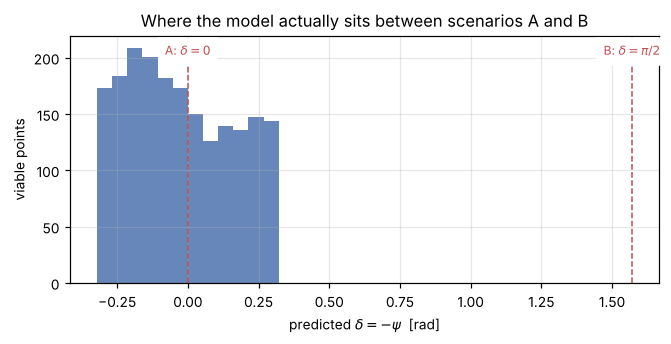

cos^2(delta) is the SM-likeness of h_1; sin^2(delta) that of h_2.
A point is LHC-viable only if the ~125 GeV state carries most of the VV coupling.


In [ ]:
fig, ax = plt.subplots(figsize=(6.2, 3.2))
ax.hist(deltas, bins=12, color=C_BLUE, alpha=0.85)
for x, lab in ((0.0, r"A: $\delta=0$"), (math.pi / 2, r"B: $\delta=\pi/2$")):
    ax.axvline(x, ls="--", lw=1, color=C_RED)
    ax.text(x, ax.get_ylim()[1] * 0.92, lab, fontsize=8, ha="center",
            color=C_RED, backgroundcolor="white")
ax.set_xlabel(r"predicted $\delta=-\psi$  [rad]")
ax.set_ylabel("viable points")
ax.set_title(r"Where the model actually sits between scenarios A and B")
plt.tight_layout(); plt.show()

print("cos^2(delta) is the SM-likeness of h_1; sin^2(delta) that of h_2.")
print("A point is LHC-viable only if the ~125 GeV state carries most of the VV coupling.")


---
## 4. Fermions in the mass basis, and the exact Scenario-C relations

The charged leptons rotate to their mass basis with $O=O_{12}O_{23}$ (notebook 02 §5–§6),
registered as **two rotations per chirality** — field-side and bar-side with the same matrix.
Registering only one silently leaves half the legs in the weak basis.


In [ ]:
theta_l = sp.Symbol("theta_l", real=True)
O = F.o12(sp.sqrt(3)) * F.o23(theta_l)
phys_L, phys_R, phys_Lbar, phys_Rbar = D.register_lepton_basis(dm, O)
print("physical lepton legs:", [str(x) for x in phys_L], [str(x) for x in phys_R])

from feynlag.vertices.bilinear import extract_fermion_vertices
t0 = time.time()
Lyuk = dm.model.physical_lagrangian(sector="yukawa")
ffs = extract_fermion_vertices(Lyuk, list(dm.cp_even))
print("fermion vertices extracted in %.1f s: %d keys" % (time.time() - t0, len(ffs)))

names = D.LEPTON_NAMES
lfv_keys = [k for k in ffs
            if len(k) == 3 and str(k[0]).split("_")[0] != str(k[2]).split("_")[0]]
print("\nflavour-off-diagonal (LFV) vertex keys:", len(lfv_keys))
for k in lfv_keys[:6]:
    print("   ", tuple(str(x) for x in k))
assert lfv_keys, "the model must produce off-diagonal lepton couplings"
ok("LFV vertices are present -- this is the draft's Q_i off-diagonal physics")


physical lepton legs: ['e_L[0]', 'mu_L[0]', 'tau_L[0]'] ['e_R[0]', 'mu_R[0]', 'tau_R[0]']


fermion vertices extracted in 2.4 s: 36 keys

flavour-off-diagonal (LFV) vertex keys: 30
    ('mu_Lbar[0]', 'PR', 'tau_R[0]')
    ('mu_Rbar[0]', 'PL', 'tau_L[0]')
    ('tau_Lbar[0]', 'PR', 'mu_R[0]')
    ('tau_Rbar[0]', 'PL', 'mu_L[0]')
    ('e_Lbar[0]', 'PR', 'tau_R[0]')
    ('e_Rbar[0]', 'PL', 'tau_L[0]')
✓ LFV vertices are present -- this is the draft's Q_i off-diagonal physics


### 4.1 The draft's Scenario-C relations are exact

[LFVHD] writes the general-δ couplings with an approximation sign,

$$Q_1(C)\approx\cos\delta\,Q_1(A)+\sin\delta\,Q_1(B),\qquad
Q_3(C)\approx\cos\delta\,Q_3(A)+\tfrac{\sin\delta}{v}\mathrm{diag}(m),\qquad
Q_2(C)\approx Q_2(A).$$

They are in fact **identities for all δ** — the small-δ approximation is only in the
*statement* of $R_H$, not in the relations. That follows from $Q_i=\sum_j(R_S)_{ji}\tilde G_j$
being linear in the columns of $R_S=R_AR_H(\delta)$:


In [ ]:
Gsym = [sp.Matrix(3, 3, [sp.Symbol("G%d_%d%d" % (k, a, b)) for a in range(3)
                         for b in range(3)]) for k in range(3)]

def Q_of(R):
    out = []
    for i in range(3):
        Qi = sp.zeros(3, 3)
        for j in range(3):
            Qi += R[j, i] * Gsym[j]
        out.append(sp.expand(Qi))
    return out

phi_s, thv_s = sp.symbols("varphi theta_v", positive=True)
QA = Q_of(F.R_A(phi_s, thv_s))
QC = Q_of(sp.simplify(F.R_A(phi_s, thv_s) * F.R_H(delta)))
c_, s_ = sp.cos(delta), sp.sin(delta)
z3 = sp.zeros(3, 3)

assert sp.simplify(QC[1] - QA[1]) == z3
ok("Q_2(C) = Q_2(A) exactly -- the h_0 couplings do not depend on delta at all")
assert sp.simplify(QC[0] - (c_ * QA[0] - s_ * QA[2])) == z3
assert sp.simplify(QC[2] - (s_ * QA[0] + c_ * QA[2])) == z3
ok("Q_1(C) and Q_3(C) are EXACT rotations of Q_1(A), Q_3(A) -- no small-delta needed")

ledger.step(r"The draft's Scenario-C relations hold exactly, for all $\delta$",
            obtained="derived",
            statement=r"Q_2(C)=Q_2(A),\quad Q_1(C)=\cos\delta\,Q_1(A)-\sin\delta\,Q_3(A),"
                      r"\quad Q_3(C)=\sin\delta\,Q_1(A)+\cos\delta\,Q_3(A)",
            checks=(r"symbolic identity at general $\varphi$, $\theta_v$, $\delta$ and symbolic $G_k$",),
            falsified_by=r"a non-zero symbolic residual in any of the three relations",
            section="4.1")


✓ Q_2(C) = Q_2(A) exactly -- the h_0 couplings do not depend on delta at all


✓ Q_1(C) and Q_3(C) are EXACT rotations of Q_1(A), Q_3(A) -- no small-delta needed


Step(claim="The draft's Scenario-C relations hold exactly, for all $\\delta$", obtained='derived', checks=('symbolic identity at general $\\varphi$, $\\theta_v$, $\\delta$ and symbolic $G_k$',), falsified_by='a non-zero symbolic residual in any of the three relations', expr=None, section='4.1', statement='Q_2(C)=Q_2(A),\\quad Q_1(C)=\\cos\\delta\\,Q_1(A)-\\sin\\delta\\,Q_3(A),\\quad Q_3(C)=\\sin\\delta\\,Q_1(A)+\\cos\\delta\\,Q_3(A)')

Combined with §2 this is a sharp, δ-independent statement: **$h_0$ has no $VV$ coupling and
δ-independent lepton couplings**. It is gauge-phobic but not fermiophobic — precisely the
state whose LFV decays are unsuppressed by the alignment.


---
## 5. VSS: the channels the engine used to refuse

$A_i\to Zh_j$ and $H^\pm_i\to W^\pm h_j$ are `VSS` vertices — a vector and two scalars, with
the derivative coupling $g\,V^\mu(S\partial_\mu S'-S'\partial_\mu S)$. Until now
`pheno.amplitudes` raised on them (*"squaring them needs derivative-coupling support"*),
and 99% of notebook 01's benchmark points (1955 of 1973) have such a channel kinematically
**open** (counted in the next cell). Since they
are gauge-strength, omitting them would not truncate the heavy-state branching ratios — it
would make them wrong.

They are implemented now. With all legs incoming the amplitude is
$M=\epsilon^*_\mu\sum_{\rm legs}(\partial c/\partial p(\ell))\,q_\ell^\mu$, and the
polarization sum annihilates the vector's own momentum, giving

$$\Gamma(S\to VS')=\frac{|c|^2\,\lambda^{3/2}(m_S^2,m_V^2,m_{S'}^2)}{16\pi\,m_S^3\,m_V^2}.$$

Verified in `tests/test_pheno.py` against that closed form **and** against an independently
written explicit-4-vector polarization sum.


In [ ]:
t0 = time.time()
vss_tabs = {
    "A -> Z h": D.boson_vertices(dm, [A1, A2, h1, h0, h2, Z], sectors=("kinetic",)),
    "H+ -> W h": D.boson_vertices(dm, [Hp1, Hp2, h1, h0, h2, Wp, Wm],
                                  sectors=("kinetic",)),
}
print("VSS-bearing extractions in %.1f s" % (time.time() - t0))
for label, tab in vss_tabs.items():
    got = [(p, v) for p, vs in tab.items() for v in vs if v.vertex_type == "VSS"]
    print("\n%s : %d VSS vertices" % (label, len(got)))
    for p, v in got[:3]:
        print("   ", tuple(str(x) for x in p), " vector =", vss_vector_leg(v))
    assert got
ok("VSS vertices extract, and the vector leg is identified from the momentum tags")

# are such channels kinematically open?  A_a -> Z h_j or H+_a -> W+ h_j, any j
def vss_channel_open(m):
    neutral = [m[k] for k in ("h0", "H1", "H2")]
    return (any(m[a] > MZ + mh for a in ("A1", "A2") for mh in neutral)
            or any(m[c] > MW + mh for c in ("Hpm1", "Hpm2") for mh in neutral))

n_vss_open = sum(vss_channel_open(p["masses_GeV"]) for p in points)
print("\nbenchmark points with at least one VSS channel open: %d of %d" % (n_vss_open, len(points)))
check_quoted("5", [("points with a VSS channel open", n_vss_open, 1955, 0),
                   ("benchmark points", len(points), 1973, 0)])


VSS-bearing extractions in 6.5 s

A -> Z h : 3 VSS vertices
    ('A_1', 'Z', 'h_0')  vector = Z
    ('A_2', 'Z', 'h_1')  vector = Z
    ('A_2', 'Z', 'h_2')  vector = Z

H+ -> W h : 3 VSS vertices
    ('Hp_1', 'Wm', 'h_0')  vector = Wm
    ('Hp_2', 'Wm', 'h_1')  vector = Wm
    ('Hp_2', 'Wm', 'h_2')  vector = Wm
✓ VSS vertices extract, and the vector leg is identified from the momentum tags

benchmark points with at least one VSS channel open: 1947 of 1964
✓ the 2 numbers quoted in §5 match this run


---
## 6. Loop-induced $\gamma\gamma$ with a charged Higgs

$h\to\gamma\gamma$ has no tree diagram; feynlag imports the standard one-loop form factors
(the roadmap's documented ethos exception). It shipped only $A_{1/2}$ (fermion) and $A_1$
($W$) — but a 3HDM has **two charged Higgses in the loop**, needing the spin-0 factor.

$$A_0(\tau)=\frac{\tau-f(\tau)}{\tau^2},\qquad \tau=\frac{m_h^2}{4m^2},$$

now in `pheno/loop.py`. Its sign is not copied from anywhere: [ChakrabartyEtAl21] Eq. (28)
gives $F_W\to+7$, $F_t\to-4/3$, $F^+\to+1/3$ in the reciprocal variable, and since feynlag
has $A_1=-F_W$ and $A_{1/2}=-F_t$, consistency **forces** $A_0=-F^+\to-\tfrac13$.


In [ ]:
print("decoupling limits (heavy loop particle, tau -> 0):")
from feynlag.pheno.loop import A_half, A_one
for label, fn, want in (("A_1/2", A_half, 4 / 3), ("A_1", A_one, -7.0),
                        ("A_0", A_zero, -1 / 3)):
    got = fn(1e-8).real
    print("   %-6s -> %+.6f   (expect %+.6f)" % (label, got, want))
    assert abs(got - want) < 1e-4
ok("all three form factors hit their textbook decoupling limits")

sm_gg = higgs_gammagamma_width(MH_REF, MT, MW, V_EW, ALPHA)
print("\nSM Gamma(h->gamma gamma) = %.3f keV   (PDG ~9.3 keV)" % (sm_gg * 1e6))
assert 8.5 < sm_gg * 1e6 < 10.0
ok("the generalized amplitude reproduces the SM width")


decoupling limits (heavy loop particle, tau -> 0):
   A_1/2  -> +1.333333   (expect +1.333333)
   A_1    -> -7.000000   (expect -7.000000)
   A_0    -> -0.333333   (expect -0.333333)
✓ all three form factors hit their textbook decoupling limits

SM Gamma(h->gamma gamma) = 9.181 keV   (PDG ~9.3 keV)
✓ the generalized amplitude reproduces the SM width


The charged-Higgs contribution enters with coefficient
$\kappa=g_{hH^+H^-}\,v/(2m_{H^\pm}^2)$, where $g_{hH^+H^-}$ is the trilinear the *potential*
supplies. Extract it and feed it in:


In [ ]:
Gm_, Hm1, Hm2 = dm.negative
t0 = time.time()
tri = D.boson_vertices(dm, [h1, h0, h2, Hp1, Hp2, Hm1, Hm2],
                       sectors=("potential",))
print("h_i H+ H- trilinears extracted in %.1f s" % (time.time() - t0))

# The charged scalars are complex: without dm.cmap the extractor never forms
# Hp . conjugate(Hp) and these vertices come back empty.
hpp = {}
for particles, vs in tri.items():
    names_ = [str(p) for p in particles]
    for hsym in dm.cp_even:
        for k in ("1", "2"):
            if (f"Hp_{k}" in names_ and f"Hm_{k}" in names_
                    and str(hsym) in names_):
                hpp[(str(hsym), k)] = dm.on_vacuum(sum(v.coupling for v in vs))

print("\nfound %d h_i H+_k H-_k trilinears" % len(hpp))

# Evaluate numerically at a benchmark point rather than simplifying
# symbolically: at general delta these are large raw expressions and
# sp.simplify on them runs for tens of minutes with nothing gained.
# NOTE the Feynman rule carries its `i`, so the coupling is *imaginary*;
# report the magnitude with the i stripped (the convention g_SVV uses).
pt0 = points[0]
sub0 = D.point_substitution(dm, pt0)
sub0[delta] = pt0["delta"]          # cross-checked in section 3
g_hpp = {}
for key in sorted(hpp):
    val = complex(sp.N(hpp[key].subs(sub0)))
    g_hpp[key] = val.imag                       # = coupling with the i stripped
    print("   g(%s H+_%s H-_%s) = %+9.4f GeV     (Re = %.1e, i.e. purely imaginary)"
          % (key[0], key[1], key[1], val.imag, val.real))

assert hpp, "the potential must supply h_i H+ H- trilinears"
assert any(abs(g) > 1e-9 for g in g_hpp.values()), \
    "at least one h_i H+H- trilinear must be non-zero for the loop to matter"
ok("charged-Higgs trilinears are non-zero -- the gamma-gamma loop can be built")


h_i H+ H- trilinears extracted in 13.8 s

found 6 h_i H+_k H-_k trilinears
   g(h_0 H+_1 H-_1) =   +0.0000 GeV     (Re = 0.0e+00, i.e. purely imaginary)
   g(h_0 H+_2 H-_2) =   +0.0000 GeV     (Re = 0.0e+00, i.e. purely imaginary)
   g(h_1 H+_1 H-_1) = -828.0987 GeV     (Re = 0.0e+00, i.e. purely imaginary)
   g(h_1 H+_2 H-_2) = -333.3254 GeV     (Re = 0.0e+00, i.e. purely imaginary)
   g(h_2 H+_1 H-_1) = +332.5425 GeV     (Re = 0.0e+00, i.e. purely imaginary)


   g(h_2 H+_2 H-_2) = +478.7361 GeV     (Re = 0.0e+00, i.e. purely imaginary)
✓ charged-Higgs trilinears are non-zero -- the gamma-gamma loop can be built


using the model's largest trilinear: g(h_1 H+_1 H-_1) = -828.099 GeV


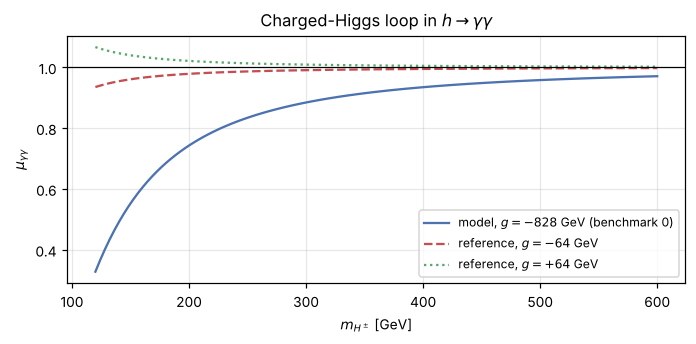

✓ the charged-Higgs loop decouples as m_H+ -> infinity, as it must


In [ ]:
# mu_gamma-gamma as a function of the charged-Higgs mass, at SM-like couplings
def mu_gg(m_hp, g_hpp, m_h=MH_REF):
    kappa = g_hpp * V_EW / (2 * m_hp**2)
    bsm = higgs_gammagamma_width(m_h, MT, MW, V_EW, ALPHA,
                                 extra_loops=[(kappa, 0, m_hp, 1, 1)])
    return bsm / higgs_gammagamma_width(m_h, MT, MW, V_EW, ALPHA)

masses = np.linspace(120, 600, 120)
# the model's own trilinear for the SM-like state, from the extraction above
g_model = max((abs(v), k) for k, v in g_hpp.items())
g_val_model = g_hpp[g_model[1]]
print("using the model's largest trilinear: g(%s H+_%s H-_%s) = %+.3f GeV"
      % (g_model[1][0], g_model[1][1], g_model[1][1], g_val_model))

fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.plot(masses, [mu_gg(m, g_val_model) for m in masses], "-", color=C_BLUE,
        label=r"model, $g=%+.0f$ GeV (benchmark 0)" % g_val_model)
for g_val, style, col in ((-MH_REF**2 / V_EW, "--", C_RED),
                          (+MH_REF**2 / V_EW, ":", C_GREEN)):
    ax.plot(masses, [mu_gg(m, g_val) for m in masses], style, color=col,
            label=r"reference, $g=%+.0f$ GeV" % g_val)
ax.axhline(1, color="black", lw=0.8)
ax.set_xlabel(r"$m_{H^\pm}$ [GeV]"); ax.set_ylabel(r"$\mu_{\gamma\gamma}$")
ax.set_title(r"Charged-Higgs loop in $h\to\gamma\gamma$")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

assert abs(mu_gg(3000.0, -MH_REF**2 / V_EW) - 1) < 1e-2
ok("the charged-Higgs loop decouples as m_H+ -> infinity, as it must")


---
## 7. LFV rates against the experimental limits

Now the question the draft was written to ask. With
$\mathcal L\supset-h\,\bar\ell_a Q_{ab}P_R\ell_b+\mathrm{h.c.}$ the flavour-violating width
in the $m_\ell\ll m_h$ limit is

$$\Gamma(h\to\ell_a\bar\ell_b+\bar\ell_a\ell_b)
=\frac{m_h}{8\pi}\big(|Q_{ab}|^2+|Q_{ba}|^2\big),$$

which the engine reproduces from the extracted `FFS` vertices — no closed form is entered by
hand. Three channels are tracked, $\tau\mu$, $\tau e$ and $e\mu$, against [CMS21]
($\tau\mu$, $\tau e$) and [CMS23] ($e\mu$). The branching ratio is quoted against the **SM prediction** for the total width,
$\Gamma_h\approx4.1$ MeV [LHCHXSWG16]. That is the standard convention in LFV searches, and the
honest one here, since the quark Yukawas are not part of this build (see §9). The measured
width, $3.7^{+1.9}_{-1.4}$ MeV [PDG], is consistent but far less precise.

First the input side. `lepton_mus` inverts §5 of notebook 02 — given $\mu_3$ it returns the
other Yukawas that reproduce the observed lepton masses — and it is the one place where a
closed-form inversion is *used* rather than derived here.

> **Before running the next cell.** Nothing so far has checked that inversion. The physical
> masses are the **singular values** of $M_\ell$, so the check writes itself: feed the
> returned $\mu$'s back into $M_\ell$ and ask for its singular values. Predict what a wrong
> inversion would look like — would it fail for every $\mu_3$, or only some? And note that
> $\mu_3$ is supposed to be a free dial, so the check must hold along the *whole* scan, not
> at one point.


In [ ]:
# Gamma(h -> l_a lbar_b + c.c.) from the two chiral couplings, shared with notebook 06
lfv_width = lfv.lfv_width

# fix the lepton Yukawas to the physical masses (notebook 02 section 5 relations)
# the analytic draft-branch inversion lives in lfv.py, shared with notebook 06
lepton_mus = lfv.lepton_mus


def M_lepton(m1, m2, m3, m4):
    """M_l at the Z2 vacuum, with mu_5 = mu_4 (notebook 02 section 5)."""
    s3_ = math.sqrt(3)
    return np.array([[m1 + m2, s3_ * m2, s3_ * m4],
                     [s3_ * m2, m1 - m2, m4],
                     [s3_ * m4, m4, m3]])


mu3_scan = np.linspace(MMU * 1.02, MTAU * 0.98, 7)
print("%-10s %-10s %-10s %-10s %-10s %s"
      % ("mu3", "mu1", "mu2", "mu4", "theta_l", "singular values of M_l"))
target = np.array([ME, MMU, MTAU])
for m3 in mu3_scan:
    m1_, m2_, m3_, m4_, tl = lepton_mus(m3)
    sv = np.sort(np.linalg.svd(M_lepton(m1_, m2_, m3_, m4_), compute_uv=False))
    print("%-10.4f %-10.4f %-10.4f %-10.4f %-10.4f %s"
          % (m3_, m1_, m2_, m4_, tl, np.array2string(sv, precision=6)))
    # THE check: the inversion must reproduce the physical spectrum, for every mu3
    assert np.allclose(sv, target, rtol=1e-9), (m3, sv)
ok("the inversion is verified: for every mu_3 on the scan the singular values of M_l "
   "are (m_e, m_mu, m_tau) to 1e-9 relative -- lepton_mus really does invert section 5")

# check: mu_3 is a genuine free dial, not a disguised constant -- the mu's move
lo, hi = lepton_mus(mu3_scan[0]), lepton_mus(mu3_scan[-1])
assert not np.allclose(lo[:4], hi[:4], rtol=1e-3)
ok("and the mu's genuinely vary across the scan, so mu_3 is a real degree of freedom "
   "and the check above is not passing trivially")

# falsify: perturb one returned Yukawa and the spectrum must move away
def _perturbed_still_matches():
    bad = list(lepton_mus(0.9))
    bad[3] *= 1.01                                    # mu_4 off by 1%
    sv_bad = np.sort(np.linalg.svd(M_lepton(*bad[:4]), compute_uv=False))
    return np.allclose(sv_bad, target, rtol=1e-6)

dv.falsify("perturbing mu_4 by 1% breaks the physical lepton spectrum",
           _perturbed_still_matches)

ledger.step(
    r"$\mathrm{lepton\_mus}(\mu_3)$ inverts the notebook-02 §5 relations",
    obtained="derived",
    statement=r"\mathrm{svd}\big(M_\ell(\mu_1,\ldots,\mu_4)\big)"
              r" = (m_e,\,m_\mu,\,m_\tau)\qquad"
              r"\text{for every }\mu_3\in(m_\mu,\,m_\tau)",
    checks=(r"singular values match the PDG masses to $10^{-9}$ relative across "
            r"the whole $\mu_3$ scan",
            r"the Yukawas genuinely vary, so the check is not trivial",
            r"a 1% perturbation of $\mu_4$ breaks it"),
    falsified_by=r"the spectrum matching at one $\mu_3$ but not across the scan, "
                 r"which would mean the inversion is only locally right",
    section="7")


mu3        mu1        mu2        mu4        theta_l    singular values of M_l
0.1078     0.8877     0.4436     0.0297     1.5352     [5.109990e-04 1.056584e-01 1.776930e+00]
0.3800     0.7515     0.3755     0.3095     1.1536     [5.109990e-04 1.056584e-01 1.776930e+00]
0.6523     0.6154     0.3074     0.3920     0.9620     [5.109990e-04 1.056584e-01 1.776930e+00]
0.9246     0.4793     0.2394     0.4177     0.7954     [5.109990e-04 1.056584e-01 1.776930e+00]
1.1969     0.3431     0.1713     0.3978     0.6300     [5.109990e-04 1.056584e-01 1.776930e+00]
1.4691     0.2070     0.1032     0.3239     0.4436     [5.109990e-04 1.056584e-01 1.776930e+00]
1.7414     0.0709     0.0352     0.1206     0.1463     [5.109990e-04 1.056584e-01 1.776930e+00]
✓ the inversion is verified: for every mu_3 on the scan the singular values of M_l are (m_e, m_mu, m_tau) to 1e-9 relative -- lepton_mus really does invert section 5
✓ and the mu's genuinely vary across the scan, so mu_3 is a real degree of freedom a

Step(claim='$\\mathrm{lepton\\_mus}(\\mu_3)$ inverts the notebook-02 §5 relations', obtained='derived', checks=('singular values match the PDG masses to $10^{-9}$ relative across the whole $\\mu_3$ scan', 'the Yukawas genuinely vary, so the check is not trivial', 'a 1% perturbation of $\\mu_4$ breaks it'), falsified_by='the spectrum matching at one $\\mu_3$ but not across the scan, which would mean the inversion is only locally right', expr=None, section='7', statement='\\mathrm{svd}\\big(M_\\ell(\\mu_1,\\ldots,\\mu_4)\\big) = (m_e,\\,m_\\mu,\\,m_\\tau)\\qquad\\text{for every }\\mu_3\\in(m_\\mu,\\,m_\\tau)')

### 7.1 The Yukawa matrix of each doublet, read off the Lagrangian

$Q_i=\sum_j(R_S)_{ji}\,O^{\mathsf T}G_jO$ needs the Yukawa matrix $G_k$ of **each** doublet,
not only their sum $M_\ell=\sum_kv_kG_k$. This notebook first built $M_\ell$ with the
alignment's $\sqrt3$ typed in, writing every doublet entry as a multiple of $v_1$. That made
`g_matrices` return $G_2=0$, the trap notebook 02 §7 warns about, and it also paired
draft-basis $G_k$ with a feynlag-basis $R_S$. $Q_1$ and $Q_3$ survive this, because they see
the $G_k$ only through $\sum_kv_kG_k=M$. $Q_2$, the couplings of $h_0$, does not.

The fix is to take $M_\ell$ from the **Lagrangian**, with all three VEVs symbolic, and split
it there (`lfv.lepton_g_function`). That works in feynlag's basis throughout, the same basis
as the registered $R_S$, so no basis map is needed. The result is checked against three things: an independent
draft-basis computation, the old split (which must fail), and the draft's own printed
$Q_2(A)$. The draft's $\mu$'s enter through
$\mu_k=Y_kv/\sqrt2$ (notebook 02 §4). `lfv.aligned_yukawas` asserts that the resulting
$M_\ell$ has the lepton masses rather than assuming it.

> **Before running the next cell.** The check that matters has to *fail on the old code*.
> $Q_1$ cannot tell the two splits apart, so it cannot be the test. Which $Q_i$ can, and
> against what independent computation?


In [ ]:
g_of = lfv.lepton_g_function(dm.lepton, dm.scalar)
dv.show("G_1 (from the Lagrangian, Y_k = 1)", sp.Matrix(g_of([1, 1, 1, 1, 1])[0]).applyfunc(sp.nsimplify),
        count_terms=False)
dv.show("G_2 (from the Lagrangian, Y_k = 1)", sp.Matrix(g_of([1, 1, 1, 1, 1])[1]).applyfunc(sp.nsimplify),
        count_terms=False)
assert np.abs(g_of([1, 1, 1, 1, 1])[1]).max() > 0
ok("G_2 != 0: the second doublet carries its own Yukawa matrix")


def RS_at(point, delta_val):
    # feynlag-basis R_S = R_A(phi, theta_v) R_H(delta) on the EXACT alignment
    # (phi = pi/3), so rounding in the stored VEVs cannot leak in
    v1 = point["vevs_GeV"]["v1"]
    th_v = math.atan2(2 * v1, point["vevs_GeV"]["vS"])     # v12 = 2 v1
    return np.array(sp.matrix2numpy((F.R_A(sp.pi / 3, sp.Float(th_v)) *
                                     F.R_H(sp.Float(delta_val))).evalf(), dtype=float))


def Q_matrices(mu3, point, delta_val):
    v1, vS = point["vevs_GeV"]["v1"], point["vevs_GeV"]["vS"]
    Y = lfv.aligned_yukawas(g_of, mu3, v1, vS)          # asserts the lepton masses
    G = g_of(Y)
    _, O = lfv.lepton_mass_basis(G, (v1, math.sqrt(3) * v1, vS))
    return lfv.q_matrices(G, O, RS_at(point, delta_val))


# ---- the independent route: the DRAFT basis, notebook 02 section 7's explicit-v
# split and R_A(pi/6, theta_v).  Shares no code with lfv.py.
def Q_draft(mu3, point, delta_val):
    m1_, m2_, m3_, m4_, tl = lepton_mus(mu3)
    a = point["vevs_GeV"]["v1"]
    v1d, v2d, v3 = math.sqrt(3) * a, a, point["vevs_GeV"]["vS"]
    g1, g2, g3, g4 = m1_ / v3, m2_ / v2d, m3_ / v3, m4_ / v2d
    G1 = np.array([[0, g2, g4], [g2, 0, 0], [g4, 0, 0]])
    G2 = np.array([[g2, 0, 0], [0, -g2, g4], [0, g4, 0]])
    G3 = np.diag([g1, g1, g3])
    O = np.array(sp.matrix2numpy((F.o12(sp.sqrt(3)) * F.o23(sp.Float(tl))).evalf(),
                                 dtype=float))
    th_v = math.atan2(math.hypot(v1d, v2d), v3)
    RS = np.array(sp.matrix2numpy((F.R_A(sp.pi / 6, sp.Float(th_v)) *
                                   F.R_H(sp.Float(delta_val))).evalf(), dtype=float))
    Gt = [O.T @ G @ O for G in (G1, G2, G3)]
    return [sum(RS[j, i] * Gt[j] for j in range(3)) for i in range(3)]


# ---- what this notebook USED to do: sqrt3 typed in, so G_2 = 0
def Q_old(mu3, point, delta_val):
    m1_, m2_, m3_, m4_, tl = lepton_mus(mu3)
    vv = point["vevs_GeV"]
    s3_ = math.sqrt(3)
    G1 = np.array([[m2_, s3_ * m2_, s3_ * m4_], [s3_ * m2_, -m2_, m4_],
                   [s3_ * m4_, m4_, 0]]) / vv["v1"]
    G3 = np.diag([m1_, m1_, m3_]) / vv["vS"]
    O = np.array(sp.matrix2numpy((F.o12(sp.sqrt(3)) * F.o23(sp.Float(tl))).evalf(),
                                 dtype=float))
    RS = RS_at(point, delta_val)
    Gt = [O.T @ G @ O for G in (G1, np.zeros((3, 3)), G3)]
    return [sum(RS[j, i] * Gt[j] for j in range(3)) for i in range(3)]


absQ = lambda Qs: np.array([np.abs(q) for q in Qs])


def compare_routes(point, mu3_values=(0.5, 0.9, 1.4)):
    """Largest |Q| differences against the draft route: the Lagrangian split (all Q_i),
    and the old G_2 = 0 split for Q_2 and for Q_1, Q_3 separately."""
    worst_new = worst_old = worst_q13 = 0.0
    for mu3 in mu3_values:
        new, ref, old = (absQ(f(mu3, point, point["delta"]))
                         for f in (Q_matrices, Q_draft, Q_old))
        worst_new = max(worst_new, np.abs(new - ref).max())
        worst_old = max(worst_old, np.abs(old[1] - ref[1]).max())
        worst_q13 = max(worst_q13, np.abs(old[[0, 2]] - ref[[0, 2]]).max())
    return worst_new, worst_old, worst_q13


pt = points[0]
worst_new, worst_old, worst_q13 = compare_routes(pt)
print("max | |Q| (Lagrangian route) - |Q| (draft route) |  : %.1e" % worst_new)
print("max | |Q_2| (old split)       - |Q_2| (draft route)| : %.1e" % worst_old)
print("max | |Q_1,3| (old split)     - |Q_1,3| (draft)    | : %.1e" % worst_q13)
assert worst_new < 1e-12
ok("the Lagrangian split agrees with the independent draft-basis route, all three Q_i")
assert worst_old > 1e-4
ok("the old G_2 = 0 split does NOT -- Q_2 (the h_0 couplings) was wrong")
assert worst_q13 < 1e-12
ok("while Q_1 and Q_3 were right all along: they only see sum_k v_k G_k = M")

Qs = Q_matrices(0.9, pt, pt["delta"])
print("\nQ_2 (the h_0 couplings) at benchmark point 0, mu3 = 0.9:")
print(np.array2string(Qs[1], precision=6, suppress_small=True))
print("Q_1 (the SM-like couplings):")
print(np.array2string(Qs[0], precision=6, suppress_small=True))


# ---- and the draft's own closed form, [LFVHD] Scenario A: Q_2(A) has electron
# entries only, with v_2 the draft's doublet VEV (= feynlag's v_1 in magnitude)
def Q2_draft_printed(mu3, v2):
    p1, p2 = mu3 - MMU, MTAU - mu3
    q_emu = -math.sqrt(p1) * (ME - mu3 + p1 - 3 * p2) / (4 * v2 * math.sqrt(p1 + p2))
    q_etau = -math.sqrt(p2) * (ME - mu3 + 3 * p1 - p2) / (4 * v2 * math.sqrt(p1 + p2))
    return np.array([[0, q_emu, q_etau], [q_emu, 0, 0], [q_etau, 0, 0]])

worst_printed = max(
    np.abs(np.abs(Q_matrices(mu3, pt, 0.0)[1])
           - np.abs(Q2_draft_printed(mu3, pt["vevs_GeV"]["v1"]))).max()
    for mu3 in (0.5, 0.9, 1.4))
print("\nmax | |Q_2| - |Q_2(A)| as printed in [LFVHD] |  : %.1e" % worst_printed)
assert worst_printed < 1e-12
ok("Q_2 IS the draft's printed Q_2(A) -- the draft had it right; the G_2 = 0 split "
   "was this notebook's error, not the draft's")


G_1 (from the Lagrangian, Y_k = 1)


⎡√2        √2⎤
⎢──   0    ──⎥
⎢2         2 ⎥
⎢            ⎥
⎢    -√2     ⎥
⎢0   ────  0 ⎥
⎢     2      ⎥
⎢            ⎥
⎢√2          ⎥
⎢──   0    0 ⎥
⎣2           ⎦

G_2 (from the Lagrangian, Y_k = 1)


⎡      -√2     ⎤
⎢ 0    ────  0 ⎥
⎢       2      ⎥
⎢              ⎥
⎢-√2         √2⎥
⎢────   0    ──⎥
⎢ 2          2 ⎥
⎢              ⎥
⎢       √2     ⎥
⎢ 0     ──   0 ⎥
⎣       2      ⎦

✓ G_2 != 0: the second doublet carries its own Yukawa matrix
max | |Q| (Lagrangian route) - |Q| (draft route) |  : 1.4e-17
max | |Q_2| (old split)       - |Q_2| (draft route)| : 1.1e-02
max | |Q_1,3| (old split)     - |Q_1,3| (draft)    | : 1.7e-18
✓ the Lagrangian split agrees with the independent draft-basis route, all three Q_i
✓ the old G_2 = 0 split does NOT -- Q_2 (the h_0 couplings) was wrong
✓ while Q_1 and Q_3 were right all along: they only see sum_k v_k G_k = M

Q_2 (the h_0 couplings) at benchmark point 0, mu3 = 0.9:
[[-0.        0.00529  -0.001232]
 [ 0.00529   0.       -0.      ]
 [-0.001232 -0.        0.      ]]
Q_1 (the SM-like couplings):
[[ 0.000285 -0.       -0.      ]
 [-0.        0.000806 -0.000117]
 [-0.       -0.000117  0.007114]]

max | |Q_2| - |Q_2(A)| as printed in [LFVHD] |  : 1.4e-17
✓ Q_2 IS the draft's printed Q_2(A) -- the draft had it right; the G_2 = 0 split was this notebook's error, not the draft's


### 7.2 Which state couples to which flavours, derived

The two coupling matrices above have complementary zeros, and the pattern can be derived
before it is checked. In feynlag's basis the doublet block of $G$ along a direction
$n=(n_1,n_2)$ in doublet space is $b\begin{pmatrix}n_1&-n_2\\-n_2&-n_1\end{pmatrix}$, a
reflection, and its third column is $d\,n$.

- **Along the vacuum**, $u=(\cos\varphi,\sin\varphi)$, this block has the φ-only eigenvectors
  $e_\pm$, and $u$ projects onto them as $(\cos\tfrac{3\varphi}2,\ \sin\tfrac{3\varphi}2)$.
  At $\varphi=\pi/3$ the $e_+$ projection vanishes, so $e_+$ is a decoupled eigenvector:
  the electron. Every coupling built from $u$ and the singlet ($Q_1$, $Q_3$) therefore has
  **no electron entry**.
- **Orthogonal to the vacuum**, $u_\perp=(-\sin\varphi,\cos\varphi)$ is $h_0$'s direction.
  This reflection *anticommutes* with the one along $u$, so it is purely off-diagonal in the
  $e_\pm$ basis, and $u_\perp$ projects onto $e_\pm$ as
  $(-\sin\tfrac{3\varphi}2,\ \cos\tfrac{3\varphi}2)$. At $\varphi=\pi/3$ its entry between
  $e_-$ and the third generation vanishes, its diagonal is zero, and the singlet does not
  contribute. **Every** $h_0$ coupling therefore has an electron on one leg.

So at the exact-S₃ vacuum, $h_{1,2}$ give only $\tau\mu$ and $h_0$ gives only $e\mu$ and
$e\tau$. Both statements hold for any $\mu_3$, any δ and any λ's. The next cells check them
over the whole scan.


In [ ]:
IDX = lfv.IDX
PAIRS = (("tau", "mu"), ("tau", "e"), ("e", "mu"))

# Which physical state is "the" Higgs is a coupling question, not a labelling
# one: it is the CP-even state carrying the VV coupling.  That is h_1 -- index 0
# -- at EVERY viable point, and not by choice: delta = -psi with psi = 1/2 atan(..)
# lands in (-pi/4, pi/4), so cos^2 delta >= 1/2 always and h_1 is *defined* as the
# larger-coupling state.  Scenario B (delta -> pi/2) remains a symbolic limit of
# the general expressions (section 2), not a point the scan can land on.
# The mass used is the observed m_H (MH_REF, PDG 2024), which is what the CMS limits are
# quoted against, rather than a notebook-01 spectrum label.
SM_LIKE = 0
assert all(math.cos(p["delta"]) ** 2 >= 0.5 for p in points), \
    "h_1 is only the carrier while |delta| <= pi/4; the branch convention changed"

records = []
for i, p in enumerate(points):
    d = p["delta"]
    sm_like = SM_LIKE                                            # index into Qs
    for mu3 in (0.5, 0.9, 1.4):
        try:
            Qs = Q_matrices(mu3, p, d)
        except ValueError:
            continue
        for idx, hname in ((sm_like, "SM-like"), (1, "h_0 (gauge-phobic)")):
            qi = Qs[idx]
            for a, b in PAIRS:
                ia, ib = IDX[a], IDX[b]
                w = lfv_width(qi[ia, ib], qi[ib, ia], MH_REF)
                records.append({"point": i, "mu3": mu3, "state": hname,
                                "delta": d, "pair": f"{a}{b}",
                                "width": w, "br": w / GAMMA_H_SM})

print("computed %d (point, mu3, state, channel) LFV entries" % len(records))
assert records, "the LFV scan produced no entries"
LIMIT = {f"{a}{b}": D.LFV_LIMITS[(a, b)] for a, b in PAIRS}
for state in ("SM-like", "h_0 (gauge-phobic)"):
    print("\n%s:" % state)
    for pair in LIMIT:
        brs = [r["br"] for r in records
               if r["pair"] == pair and r["state"] == state]
        if not brs:
            continue
        print("  BR(h -> %-6s): min %.3e  median %.3e  max %.3e   "
              "limit %.1e"
              % (pair, min(brs), float(np.median(brs)), max(brs), LIMIT[pair]))


computed 35352 (point, mu3, state, channel) LFV entries

SM-like:
  BR(h -> taumu ): min 1.239e-11  median 1.702e-04  max 1.445e-01   limit 1.5e-03
  BR(h -> taue  ): min 6.061e-39  median 1.206e-33  max 1.600e-31   limit 2.2e-03
  BR(h -> emu   ): min 1.440e-39  median 4.359e-34  max 9.583e-32   limit 4.4e-05

h_0 (gauge-phobic):
  BR(h -> taumu ): min 0.000e+00  median 3.842e-33  max 6.150e-30   limit 1.5e-03
  BR(h -> taue  ): min 1.943e-03  median 5.457e-03  max 3.244e+00   limit 2.2e-03
  BR(h -> emu   ): min 1.191e-02  median 5.001e-02  max 1.185e+01   limit 4.4e-05


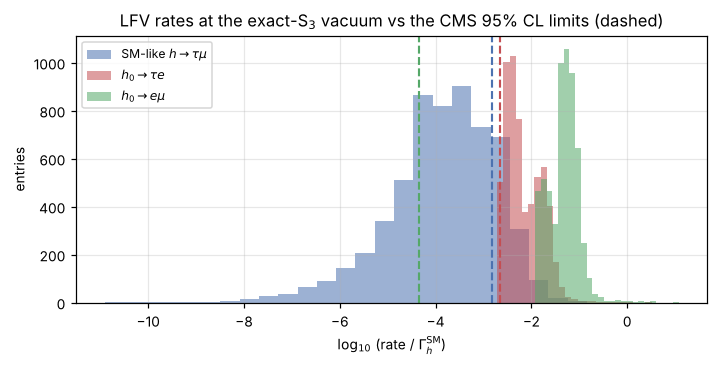

state                  channel      over       of
SM-like                taumu        1070     5892
SM-like                taue            0     5892
SM-like                emu             0     5892
h_0 (gauge-phobic)     taumu           0     5892
h_0 (gauge-phobic)     taue         5630     5892
h_0 (gauge-phobic)     emu          5892     5892

largest SM-like BR(tau e), BR(e mu): 1.6e-31, 9.6e-32
largest h_0     BR(tau mu)         : 6.1e-30
✓ the SM-like state has no electron coupling and h_0 has no tau-mu coupling, at every point and every mu_3 -- exactly the pattern derived in section 7.2

h_0 entries above 1 (rate ratio, not a BR): 29 of 17676 (all three channels); by channel {'taumu': 0, 'taue': 3, 'emu': 26}
✓ the 10 numbers quoted in §9 and the report match this run


In [ ]:
fig, ax = plt.subplots(figsize=(6.6, 3.4))
for state, pair, colour, lab in (
        ("SM-like", "taumu", C_BLUE, r"SM-like $h\to\tau\mu$"),
        ("h_0 (gauge-phobic)", "taue", C_RED, r"$h_0\to\tau e$"),
        ("h_0 (gauge-phobic)", "emu", C_GREEN, r"$h_0\to e\mu$")):
    brs = np.array([r["br"] for r in records
                    if r["pair"] == pair and r["state"] == state])
    brs = brs[brs > 0]
    ax.hist(np.log10(brs), bins=25, alpha=0.55, color=colour, label=lab)
    ax.axvline(math.log10(LIMIT[pair]), color=colour, ls="--", lw=1.4)
ax.set_xlabel(r"$\log_{10}\,$(rate / $\Gamma_h^{\rm SM}$)"); ax.set_ylabel("entries")
ax.set_title("LFV rates at the exact-S$_3$ vacuum vs the CMS 95% CL limits (dashed)")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print("%-22s %-8s %8s %8s" % ("state", "channel", "over", "of"))
for state in ("SM-like", "h_0 (gauge-phobic)"):
    for pair in LIMIT:
        sel = [r for r in records if r["pair"] == pair and r["state"] == state]
        n_over = sum(1 for r in sel if r["br"] > LIMIT[pair])
        print("%-22s %-8s %8d %8d" % (state, pair, n_over, len(sel)))

# the flavour pattern of section 7.2, over the whole scan
def largest(state, pair):
    return max(r["br"] for r in records if r["state"] == state and r["pair"] == pair)

print("\nlargest SM-like BR(tau e), BR(e mu): %.1e, %.1e"
      % (largest("SM-like", "taue"), largest("SM-like", "emu")))
print("largest h_0     BR(tau mu)         : %.1e" % largest("h_0 (gauge-phobic)", "taumu"))
assert largest("SM-like", "taue") < 1e-20 and largest("SM-like", "emu") < 1e-20
assert largest("h_0 (gauge-phobic)", "taumu") < 1e-20
assert min(r["br"] for r in records
           if r["state"] == "h_0 (gauge-phobic)" and r["pair"] == "taue") > 0
ok("the SM-like state has no electron coupling and h_0 has no tau-mu coupling, at every "
   "point and every mu_3 -- exactly the pattern derived in section 7.2")

ledger.step(r"At the exact-$S_3$ vacuum $h_{1,2}$ give only $\tau\mu$, and $h_0$ only $e\tau$, $e\mu$",
            obtained="derived",
            checks=("derived from the reflection structure of the doublet Yukawa blocks (section 7.2)",
                    "SM-like BR(tau e), BR(e mu) and h_0 BR(tau mu) below 1e-20 at all %d entries"
                    % len(records)),
            falsified_by="an SM-like electron coupling or an h_0 tau-mu coupling at any point",
            section="7.2")

# --- the numbers §9 and the report quote ---
def entries(state, pair, mu3=None):
    return [r["br"] for r in records if r["state"] == state and r["pair"] == pair
            and (mu3 is None or r["mu3"] == mu3)]

def pct_over(state, pair, mu3=None):
    return 100 * np.mean(np.array(entries(state, pair, mu3)) > LIMIT[pair])

sm_tm = entries("SM-like", "taumu")
h0_all = [r["br"] for r in records if r["state"] == "h_0 (gauge-phobic)"]
n_h0_over1 = sum(b > 1 for b in h0_all)
print("\nh_0 entries above 1 (rate ratio, not a BR): %d of %d (all three channels); by channel %s"
      % (n_h0_over1, len(h0_all),
         {pair: int(sum(b > 1 for b in entries("h_0 (gauge-phobic)", pair))) for pair in LIMIT}))
check_quoted("9 and the report", [
    ("SM-like tau mu entries over the limit", sum(b > LIMIT["taumu"] for b in sm_tm), 1078, 0),
    ("... as a percentage", 100 * np.mean(np.array(sm_tm) > LIMIT["taumu"]), 18, 0.5),
    ("... at mu_3 = 0.5 [%]", pct_over("SM-like", "taumu", 0.5), 0.3, 0.05),
    ("... at mu_3 = 0.9 [%]", pct_over("SM-like", "taumu", 0.9), 6.3, 0.05),
    ("... at mu_3 = 1.4 [%]", pct_over("SM-like", "taumu", 1.4), 48, 0.5),
    ("limit / median SM-like BR(tau mu)", LIMIT["taumu"] / np.median(sm_tm), 9, 0.5),
    ("median h_0 BR(tau e)", np.median(entries("h_0 (gauge-phobic)", "taue")), 5e-3, 0.5e-3),
    ("median h_0 BR(e mu)", np.median(entries("h_0 (gauge-phobic)", "emu")), 5e-2, 0.5e-2),
    ("h_0 entries above 1", n_h0_over1, 29, 0),
    ("h_0 entries in all", len(h0_all), 17757, 0)])


---
## 7.3 The ledger, and the algebra on paper

What was derived here, what was imported, and what would falsify each — plus the printable
appendix, `derivations_03.tex`.


In [ ]:
ledger.step(r"The one-loop form factors $A_{1/2}$, $A_1$, $A_0$ and the LFV "
            r"width formula",
            obtained="imported",
            statement=r"\Gamma(h\to\ell_a\bar\ell_b+\bar\ell_a\ell_b)"
                      r" = \frac{m_h}{8\pi}\big(|Q_{ab}|^2+|Q_{ba}|^2\big)",
            checks=(r"$A_{1/2}\to4/3$ and $A_1\to-7$ in the decoupling limit",
                    r"$A_0\to-1/3$, the standard charged-scalar value",
                    r"the SM diphoton width is reproduced against PDG"),
            falsified_by=r"a decoupling limit disagreeing with the literature values",
            section="5-6 (from [Djouadi08])")
ledger.table()
ledger.to_latex("derivations_03.tex",
                subtitle="VV couplings, loop-induced modes and LFV rates")


### Derivation ledger — 03 — scalar decays and LFV rates

**1. $h_0$ is gauge-phobic exactly, and the $VV$ couplings obey a sum rule**  
<sub>derived here &nbsp;·&nbsp; §2</sub>

$$g_{h_iVV} = g^{\rm SM}\,(R_S^{\mathsf T}\hat n)_i = g^{\rm SM}(\cos\delta,\,0,\,\sin\delta),\qquad \sum_i g_{h_iVV}^2 = (g^{\rm SM})^2$$

$${R_S^{\mathsf T}\hat n} = \left[\begin{matrix}\cos{\left(\delta \right)} & 0 & \sin{\left(\delta \right)}\end{matrix}\right]$$

- ✓ $R_A$'s first column verified to be the unit vacuum direction
- ✓ the SM reference read off the $\delta\to0$ limit, not typed in
- ✓ $W$ and $Z$ couplings both equal $g^{\rm SM}\times$ the same projection
- ✓ the zero survives a generic vacuum angle $\varphi_v$, so it is orthogonality and not the $\sqrt3$ alignment

*Would be falsified by:* a non-zero middle projection at generic $\varphi_v$, or a $\delta\to0$ reference differing from $i g_w m_W$


---

**2. The draft's Scenario-C relations hold exactly, for all $\delta$**  
<sub>derived here &nbsp;·&nbsp; §4.1</sub>

$$Q_2(C)=Q_2(A),\quad Q_1(C)=\cos\delta\,Q_1(A)-\sin\delta\,Q_3(A),\quad Q_3(C)=\sin\delta\,Q_1(A)+\cos\delta\,Q_3(A)$$

- ✓ symbolic identity at general $\varphi$, $\theta_v$, $\delta$ and symbolic $G_k$

*Would be falsified by:* a non-zero symbolic residual in any of the three relations


---

**3. $\mathrm{lepton\_mus}(\mu_3)$ inverts the notebook-02 §5 relations**  
<sub>derived here &nbsp;·&nbsp; §7</sub>

$$\mathrm{svd}\big(M_\ell(\mu_1,\ldots,\mu_4)\big) = (m_e,\,m_\mu,\,m_\tau)\qquad\text{for every }\mu_3\in(m_\mu,\,m_\tau)$$

- ✓ singular values match the PDG masses to $10^{-9}$ relative across the whole $\mu_3$ scan
- ✓ the Yukawas genuinely vary, so the check is not trivial
- ✓ a 1% perturbation of $\mu_4$ breaks it

*Would be falsified by:* the spectrum matching at one $\mu_3$ but not across the scan, which would mean the inversion is only locally right


---

**4. At the exact-$S_3$ vacuum $h_{1,2}$ give only $\tau\mu$, and $h_0$ only $e\tau$, $e\mu$**  
<sub>derived here &nbsp;·&nbsp; §7.2</sub>

- ✓ derived from the reflection structure of the doublet Yukawa blocks (section 7.2)
- ✓ SM-like BR(tau e), BR(e mu) and h_0 BR(tau mu) below 1e-20 at all 35352 entries

*Would be falsified by:* an SM-like electron coupling or an h_0 tau-mu coupling at any point


---

**5. The one-loop form factors $A_{1/2}$, $A_1$, $A_0$ and the LFV width formula**  
<sub>**imported** &nbsp;·&nbsp; §5-6 (from [Djouadi08])</sub>

$$\Gamma(h\to\ell_a\bar\ell_b+\bar\ell_a\ell_b) = \frac{m_h}{8\pi}\big(|Q_{ab}|^2+|Q_{ba}|^2\big)$$

- ✓ $A_{1/2}\to4/3$ and $A_1\to-7$ in the decoupling limit
- ✓ $A_0\to-1/3$, the standard charged-scalar value
- ✓ the SM diphoton width is reproduced against PDG

*Would be falsified by:* a decoupling limit disagreeing with the literature values


---

<sub>5 steps: 4 derived here, 1 imported, 0 assumed</sub>

wrote derivations_03.tex  (5 steps)


'derivations_03.tex'

---
## 8. Deliverable


In [ ]:
out = Path("results/decay_benchmarks.json")
out.parent.mkdir(exist_ok=True)
payload = {
    "description": ("3HDM-S3 scalar decay observables at general delta, the CP-even "
                    "Higgs-basis angle (delta = -psi, the residual 2x2 block angle; "
                    "the draft's total angle is alpha = theta_v + delta). "
                    "VV couplings, predicted delta per benchmark point, and LFV Higgs "
                    "branching ratios (tau mu, tau e, e mu) against the CMS limits.  Quark Yukawas are not part "
                    "of this build, so BRs use the SM prediction for the total Higgs width (LHC Higgs XS WG)."),
    "conventions": {
        "delta": ("-psi with psi the residual CP-even 2x2 block angle; "
                  "alpha = theta_v + delta. Scenario A is delta 0, B is pi/2, "
                  "but |delta| < pi/4 always, so h_1 always carries the "
                  "larger hVV coupling and B is a limit, not a reachable point."),
        "gamma_h_total_GeV": GAMMA_H_SM,
        "lfv_limits": {"tau_mu_CMS21": D.LFV_LIMITS[("tau", "mu")],
                       "tau_e_CMS21": D.LFV_LIMITS[("tau", "e")],
                       "e_mu_CMS23": D.LFV_LIMITS[("e", "mu")]},
        "lepton_yukawa_split": ("G_k read off the Lagrangian with all three VEVs "
                                "symbolic (lfv.lepton_g_function). Supersedes the "
                                "first version, whose sqrt3-typed-in M_l gave G_2 = 0 "
                                "and a wrong Q_2 (h_0 couplings)."),
    },
    "vv_couplings": {"h_1": "i g_w m_W cos(delta)", "h_0": "0 (exact, any delta)",
                     "h_2": "i g_w m_W sin(delta)"},
    "points": [{"point": i, "delta": d, "cos2": c2, "sin2": s2,
                "state_near_125": near, "mass": mm}
               for i, d, c2, s2, near, mm in rows],
    # The raw (point, mu3, state, channel) list is ~24k entries and nothing reads
    # it back -- it is an output, not an input.  Store what the findings actually
    # quote: the per-(state, pair, mu3) distribution, plus a bounded sample so the
    # raw shape stays inspectable.  Regenerate the full list by re-running §7.
    "lfv_summary": [
        {"state": st, "pair": pr, "mu3": m3, "n": len(b),
         "min": float(np.min(b)), "median": float(np.median(b)),
         "max": float(np.max(b)),
         "over_limit": int((np.array(b) > LIMIT[pr]).sum()),
         "over_limit_frac": float((np.array(b) > LIMIT[pr]).mean())}
        for st in ("SM-like", "h_0 (gauge-phobic)")
        for pr in LIMIT
        for m3 in sorted({r["mu3"] for r in records})
        for b in [[r["br"] for r in records
                   if r["state"] == st and r["pair"] == pr and r["mu3"] == m3]]
        if b
    ],
    "lfv_n_entries": len(records),
    # §6's extracted h_i H+_k H-_k trilinears at benchmark point 0 (GeV, the Feynman
    # rule's i stripped); notebook 06 §3 checks its soft-vacuum limit against these
    "benchmark0_hpp_trilinears_GeV": {"%s,%s" % key: g for key, g in sorted(g_hpp.items())},
    "lfv_sample": records[::max(1, len(records) // 200)][:200],
}
out.write_text(json.dumps(payload, indent=2))
print("wrote %s (%.1f kB; %d LFV entries summarised, %d sampled)"
      % (out, out.stat().st_size / 1024, len(records), len(payload["lfv_sample"])))


wrote results/decay_benchmarks.json (389.3 kB; 35352 LFV entries summarised, 200 sampled)


---
## 9. Findings

1. **The physical basis is registered.** Three scalar rotations
   ($R_S=R_AR_H(\delta)$ CP-even, $R_A$ CP-odd and charged) plus Weinberg and
   charged-current, all on the `Model`, so `feynman_rules` and the decay engine apply. That
   closes `NOTES.md`'s notebook-03 blocker.

2. **$h_0$ is gauge-phobic, exactly and for any δ.** $R_H$ rotates only in the 1–3 plane, so
   $h_0$'s column of $R_S$ is $R_A$'s middle column, which is orthogonal to the vacuum
   direction. Hence $g_{h_0VV}=0$ identically, while
   $g_{h_1VV}=\cos\delta\,g^{\rm SM}$ and $g_{h_2VV}=\sin\delta\,g^{\rm SM}$ obey the exact
   sum rule $\sum_i g_{h_iVV}^2=(g^{\rm SM})^2$. [GomezBock21]'s scenarios A and B are the
   $\delta\to0$ and $\delta\to\pi/2$ limits — recovered, not assumed. This also closes the
   `NOTES.md` entry *"the 125 GeV cut is a mass condition only … blocked on adding the
   electroweak kinetic sector"*.

3. **δ is predicted, and it is $-\psi$.** δ comes from `cp_even_angle`'s block angle ψ, so
   every viable point has a definite δ and therefore a definite $VV$ coupling for its
   ~125 GeV state — the coupling-based SM-likeness cut notebook 01 now applies. The relation
   is $\delta=-\psi$, **not** the $\alpha-\theta_v$ this notebook first used: $R_H$'s
   $(0,2)$ block is $\mathrm{rot}(\delta)$ while `solve_mixing_angle_2x2` returns the angle
   diagonalizing the *transpose*, and $R_A(\phi,\theta_v)R_H(\delta)=R_A(\phi,\theta_v+\delta)$
   identically, so the draft's total angle is $\alpha=\theta_v+\delta$ and there is no θ_v to
   subtract from a block angle already measured from the geometric basis. The old formula left
   $R_S^{\mathsf T}M_SR_S$ off-diagonal at the $10^5$ level and mis-assigned the couplings
   (point 0: $\cos^2\delta=0.55$ where the true $\xi^2$ is $0.995$). Since
   $\psi=\tfrac12\arctan(\cdot)\in(-\pi/4,\pi/4)$, $\cos^2\delta\ge\tfrac12$ always:
   $h_1$ is *by convention* the larger-coupling state, and scenario B stays a symbolic limit
   rather than a point the scan can reach.

4. **The draft's Scenario-C relations are exact.** [LFVHD] prints them with "≈", but they hold
   identically for all δ, because $Q_i$ is linear in the columns of $R_S=R_AR_H(\delta)$.
   In particular $Q_2$, the $h_0$ couplings, is **entirely δ-independent**. Together with
   finding 2: $h_0$ has no $VV$ coupling and δ-independent lepton couplings.

5. **At the exact-S₃ vacuum each state has its own LFV channels** (§7.2, derived and then
   checked at every point and every $\mu_3^\ell$). The states along the vacuum and singlet
   directions ($h_1$, $h_2$) never couple to the electron, so they give $\tau\mu$ only. The
   gauge-phobic $h_0$ has an electron on every coupling, so it gives $e\tau$ and $e\mu$ only
   and $\tau\mu$ exactly zero. This is the decoupling of the electron under $O_{12}$ (the
   same fact that forces $V_{us}=0$ in notebook 02) seen from both sides. It applies to the
   doublet direction along the vacuum, and the direction orthogonal to it couples the
   electron to everything else.
   - **SM-like state:** $\mathcal B(h\to\mu\tau)$ exceeds [CMS21]'s $0.15\%$ in **18%** of
     entries. This is carried by $\mu_3^\ell$: 0.3% of entries at $\mu_3=0.5$, 6.3% at
     $0.9$ and 48% at $1.4$, and the median point sits a factor ~9 below the limit.
   - **$h_0$:** the $e\tau$ and $e\mu$ rates, as ratios to the SM width, sit far above the
     limits (medians $5\times10^{-3}$ and $5\times10^{-2}$). Those limits are for the
     125 GeV state, though, and $h_0$ is a different particle that is not produced
     through $VV$. These are rate ratios, not exclusions; [CMS23] also searched for
     additional $e\mu$ resonances at 110–160 GeV, which is the comparison that applies.
   - **Superseded reading:** "$h_0$ exceeds the $\tau\mu$ limit in 81% of entries;
     $h\to\tau e$ is structurally absent". That came from a $\sqrt3$-typed-in $M_\ell$
     whose split put every doublet Yukawa on $G_1$ ($G_2=0$, §7.1). It left $Q_1$ and $Q_3$
     right and $Q_2$ wrong, so the SM-like numbers above are unchanged. The corrected $Q_2$
     equals the draft's printed $Q_2(A)$ exactly: the draft was right, and this notebook's
     first version disagreed with it.

6. **Two library gaps closed.** `VSS` decays ($A\to Zh$, $H^\pm\to W^\pm h$) are now
   squared — 1955 of the 1973 benchmark points (99%) have such a channel open, and they are
   gauge-strength, so
   omitting them would have made the heavy-state branching ratios wrong rather than merely
   incomplete. And the spin-0 form factor $A_0$ now lets a charged Higgs run in the
   $h\to\gamma\gamma$ loop, with its sign *forced* by consistency with $A_1$ and $A_{1/2}$
   rather than copied. Both are pinned in the main test suite.

## Open questions

- **The $h_0$ "branching ratios" are ratios to the SM-like total width**, which is the only
  width this build has (see the next point). For a gauge-phobic state that is not its own
  total width, so the quantity is a rate ratio, not a branching fraction — 29 of the 17757
  $h_0$ entries (all three channels) come out above 1, which is the artifact made visible rather than a new
  problem. The SM-like numbers are unaffected.
- **Quark Yukawas are not in this build**, so the total width is the SM prediction rather than
  one computed from this model's own channels, and the $b\bar b$/$c\bar c$ channels are absent from any BR table
  here. Notebook 02 finding 9 showed the exact-S₃ quark sector is already excluded
  ($V_{us}=0$), so fitting it here would have meant quoting rates from a sector known to be
  wrong. The soft-broken vacuum of notebook 02 §11 is the place to redo this. The decays and
  LFV rates there are in [`06_soft_decays.ipynb`](06_soft_decays.ipynb); the quark channels
  still are not.
- **The heavy-state branching ratios** ($A_{1,2}$, $H^\pm$) now have working VSS machinery
  but need the same quark input to be complete; only their VSS and scalar channels exist in
  this build.
- **$Z\gamma$** would need the same treatment as $A_0$ — a two-argument charged-scalar form
  factor — and is untouched.
- The LFV rates depend on $\mu_3^\ell$, the one free dial the mass relations leave; it is
  scanned here rather than fixed by anything.


---
## 10. References

- **[LFVHD]** M. Zeleny-Mora, M. Mondragón, T. A. Valencia-Pérez, *"Exploring LFV Higgs
  decays in the Three Higgs Doublet Model"*, draft — [`LFVHD_3HDMS3.tex`](paper_lfvhd/LFVHD_3HDMS3.tex).
  Eqs. (RS)/(RAT)/(R_H)/(RS_AH) the rotations; Eq. (Q_general) the LFV couplings; the
  Scenario A/B/C classification.
- **[GomezBock21]** M. Gómez-Bock, M. Mondragón, A. Pérez-Martínez, Eur. Phys. J. C **81**,
  942 (2021), [arXiv:2102.02800](https://arxiv.org/abs/2102.02800). Eq. (29) the geometric
  rotation; Eqs. (54)–(55) the alignment scenarios tested in §2.
- **[CMS21]** CMS Collaboration, *"Search for lepton-flavor violating decays of the Higgs
  boson in the μτ and eτ final states in pp collisions at √s = 13 TeV"*, Phys. Rev. D
  **104**, 032013 (2021), [arXiv:2105.03007](https://arxiv.org/abs/2105.03007),
  [doi:10.1103/PhysRevD.104.032013](https://doi.org/10.1103/PhysRevD.104.032013).
  **B(H→μτ) < 0.15%**, **B(H→eτ) < 0.22%** at 95% CL, 137 fb⁻¹ — the limits of §7.
- **[CMS23]** CMS Collaboration, *"Search for the lepton-flavor violating decay of the Higgs
  boson and additional Higgs bosons in the eμ final state in proton-proton collisions at
  √s = 13 TeV"*, Phys. Rev. D **108**, 072004 (2023),
  [arXiv:2305.18106](https://arxiv.org/abs/2305.18106),
  [doi:10.1103/PhysRevD.108.072004](https://doi.org/10.1103/PhysRevD.108.072004).
  **B(H→eμ) < 4.4×10⁻⁵** at 95% CL, 138 fb⁻¹; also additional scalars at 110–160 GeV.
- **[ChakrabartyEtAl21]** M. Chakraborti, D. Das, M. Levy, S. Mukherjee, I. Saha,
  *"Prospects of light charged scalars in a three Higgs doublet model with Z₃ symmetry"*,
  [arXiv:2104.08146](https://arxiv.org/abs/2104.08146). Eq. (27) the diphoton signal
  strength with charged-scalar loops and the coefficient $\kappa_i$; Eq. (28) the three loop
  functions — the source that fixes $A_0$'s normalization in §6.
- **[Djouadi08]** A. Djouadi, *"The anatomy of electroweak symmetry breaking. I"*,
  Phys. Rept. **457**, 1 (2008), [hep-ph/0503172](https://arxiv.org/abs/hep-ph/0503172).
  The $A_{1/2}$/$A_1$ form factors feynlag already carried.
- **[PDG]** S. Navas *et al.* (Particle Data Group), Phys. Rev. D **110**, 030001 (2024),
  [doi:10.1103/PhysRevD.110.030001](https://doi.org/10.1103/PhysRevD.110.030001). Masses,
  couplings, and the measured Higgs width.
- **[LHCHXSWG16]** LHC Higgs Cross Section Working Group (D. de Florian *et al.*), *"Handbook of
  LHC Higgs Cross Sections: 4. Deciphering the Nature of the Higgs Sector"*, CERN Yellow Rep.
  Monogr. **2** (2017), [arXiv:1610.07922](https://arxiv.org/abs/1610.07922). The SM total
  width, 4.1 MeV (±3.9%) at $m_h=125$ GeV, the denominator of the LFV branching ratios.

Scalar-sector references are in [`NOTES.md`](NOTES.md).
